# 08 · Results and analysis — ThreatGraph-LD

**Goal:** show what the integrated database lets us *ask* and *see*. Four open cyber-threat datasets, one identifier (`CVE`), one technique code (`ATT&CK`):

| Source | What it says | Joins on |
|---|---|---|
| **CISA KEV** | this vulnerability *has been exploited in the wild* | `cve_id` |
| **NVD** | how severe it is (CVSS), which weakness (CWE) | `cve_id` |
| **CTID PKEV** | *how* it is exploited and what it does, in ATT&CK terms (expert mapping) | `cve_id` → `technique_id` |
| **MITRE ATT&CK** | the techniques and the tactics (attacker goals) | `technique_id` |

Everything below is computed **from the database** (Django ORM and SQL). Part 0 re-computes the headline numbers from the CSV files with a different code path and checks they agree. Figures are written to `docs/figures/` as PNG (300 dpi) and PDF (vector), with captions in `docs/figures/captions.md`.

**How to read the results.** KEV is a list of vulnerabilities *known to be exploited*, not a random sample of all vulnerabilities; so these are statements about KEV, not about "all CVEs". PKEV maps only part of KEV. Differences are associations, not causes.

In [1]:
import sys, os, json, math, itertools, textwrap, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "sources.yaml").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "webapp")]
os.environ["DJANGO_SETTINGS_MODULE"] = "threatgraph_site.settings"; os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"
import django; django.setup()
import numpy as np, pandas as pd, networkx as nx
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown
from django.db import connection
from django.db.models import Count, Q
from threatgraph import config, cleaning as C
import catalog.models as M
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30, "display.max_colwidth", 70, "display.width", 200)
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
assert json.loads((ROOT / "docs" / "phase5_validation_report.json").read_text())["all_passed"], "Phase 5 gate not passed"
assert M.Vulnerability.objects.count() == 1391, "database is empty: python manage.py load_clean_data"

# ---- paper style: serif (STIX, bundled with matplotlib), hairline axes, light solid grid, no top/right frame
INK, INK2, GRID, GRAY = "#0b0b0b", "#52514e", "#e6e5e1", "#b9b8b1"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"            # categorical slots 1-3 (validated all-pairs, colour-blind safe)
SEQ = ["#cde2fb", "#9ec5f4", "#5598e7", "#256abf", "#184f95", "#0d366b"]    # one-hue sequential ramp (blue)
ORD = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]                          # ordered categories (LOW..CRITICAL)
mpl.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "font.size": 9.5, "axes.titlesize": 10, "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8.5, "axes.edgecolor": INK2, "axes.linewidth": 0.6, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 300,
    "figure.facecolor": "white", "axes.facecolor": "white", "pdf.fonttype": 42})
CAPTIONS = {}
def finish(fig, name, insight, caption):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show(); CAPTIONS[name] = (insight, caption)
    display(Markdown(f"**Insight.** {insight}\n\n*{caption}*"))
def panel(ax, text): ax.set_title(text, loc="left", fontsize=10, fontweight="bold", color=INK)
def hgrid(ax): ax.grid(axis="x"); ax.tick_params(axis="y", length=0)
def vgrid(ax): ax.grid(axis="y"); ax.tick_params(axis="x", length=0)
print("Django", django.get_version(), "| networkx", nx.__version__, "| matplotlib", mpl.__version__)

Django 5.2.18 | networkx 3.6.1 | matplotlib 3.11.2


## 0 · Data from the database, and an independent check
One query per table, loaded into pandas. Then the headline numbers are **recomputed from the CSV files** (different code: pandas on `data/clean/`, no ORM) and compared. If any number differs the notebook stops.

In [2]:
vul = pd.DataFrame(M.Vulnerability.objects.annotate(n_map=Count("mappings", distinct=True))
      .values("cve_id", "vendor_project", "product", "date_added", "due_date", "ransomware_use", "due_before_added", "n_map",
              "nvd__cvss_v31_score", "nvd__cvss_v31_severity", "nvd__vuln_status")).rename(columns=lambda c: c.replace("nvd__", ""))
vul["date_added"] = pd.to_datetime(vul.date_added); vul["due_date"] = pd.to_datetime(vul.due_date)
vul["year"] = vul.date_added.dt.year; vul["mapped"] = vul.n_map > 0; vul["ransom"] = vul.ransomware_use == "known"
mp  = pd.DataFrame(M.PkevMapping.objects.values("mapping_id", "cve_id", "technique_id", "mapping_type"))
tl  = pd.DataFrame(M.AttackTechniqueTactic.objects.values("technique_id", "tactic__shortname")).rename(columns={"tactic__shortname": "tactic"})
Tn  = dict(M.AttackTechnique.objects.values_list("technique_id", "name"))
kc  = pd.DataFrame(M.KevCwe.objects.values("cve_id", "cwe_id", "cwe__is_informative"))
nc  = pd.DataFrame(M.NvdCveCwe.objects.values("cve_id", "cwe_id", "cwe__is_informative"))
N = len(vul)
R = dict(n_kev=N, n_ransom=int(vul.ransom.sum()), n_mapped=int(vul.mapped.sum()), n_critical=int((vul.cvss_v31_severity == "CRITICAL").sum()),
         n_cvss=int(vul.cvss_v31_score.notna().sum()), n_inf_cwe_nvd=int(nc[nc["cwe__is_informative"]].cve_id.nunique()),
         top_vendor=vul.vendor_project.value_counts().index[0], top_vendor_n=int(vul.vendor_project.value_counts().iloc[0]),
         top_tech=mp.technique_id.value_counts().index[0], top_tech_n=int(mp.technique_id.value_counts().iloc[0]),
         cov_by_year={int(k): round(float(v), 4) for k, v in vul.groupby("year").mapped.mean().items()},
         window21=int(((vul.due_date - vul.date_added).dt.days == 21).sum()),
         n_both_roles=len(set(mp[mp.mapping_type == "exploitation_technique"].cve_id) & set(mp[mp.mapping_type == "primary_impact"].cve_id)), n_tech_used=int(mp.technique_id.nunique()), n_mappings=len(mp))
# ---- independent recount from the CSV files (pandas only)
T = {t: C.read_clean(t, config.CLEAN_DIR) for t in ["kev_vulnerability", "nvd_cve", "nvd_cve_cwe", "pkev_mapping"]}
k_, n_, c_, p_ = T["kev_vulnerability"], T["nvd_cve"], T["nvd_cve_cwe"], T["pkev_mapping"]
chk = {"n_kev": len(k_), "n_ransom": int((k_.ransomware_use == "known").sum()), "n_mapped": p_.cve_id.nunique(),
       "n_critical": int((n_.cvss_v31_severity == "CRITICAL").sum()), "n_cvss": int(n_.cvss_v31_score.notna().sum()),
       "n_inf_cwe_nvd": c_[c_.is_informative].cve_id.nunique(), "top_vendor": k_.vendor_project.value_counts().index[0],
       "top_vendor_n": int(k_.vendor_project.value_counts().iloc[0]), "top_tech": p_.technique_id.value_counts().index[0],
       "top_tech_n": int(p_.technique_id.value_counts().iloc[0]), "window21": int(((k_.due_date - k_.date_added).dt.days == 21).sum()),
       "n_tech_used": p_.technique_id.nunique(), "n_mappings": len(p_),
       "n_both_roles": len(set(p_[p_.mapping_type == "exploitation_technique"].cve_id) & set(p_[p_.mapping_type == "primary_impact"].cve_id))}
cov_csv = k_.assign(m=k_.cve_id.isin(p_.cve_id), y=k_.date_added.dt.year).groupby("y").m.mean().round(4).to_dict()
bad = {k: (R[k], v) for k, v in chk.items() if R[k] != v}
assert not bad and {int(k): v for k, v in cov_csv.items()} == R["cov_by_year"], bad
print(f"OK: {len(chk) + 1} headline numbers from the database == recount from the CSV files")

OK: 15 headline numbers from the database == recount from the CSV files


## 1 · What was integrated

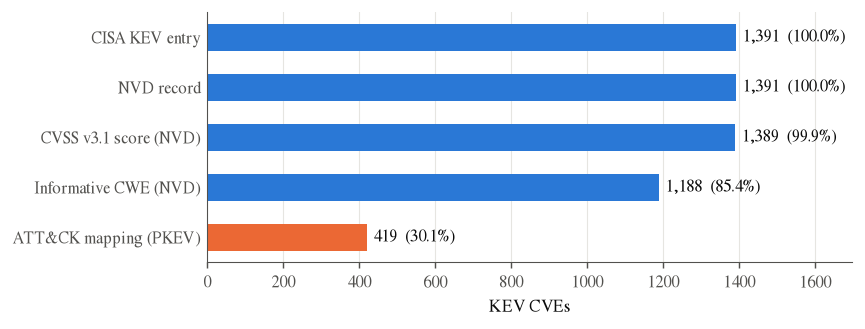

**Insight.** Three of the four sources cover almost every KEV CVE; the expert ATT&CK mapping (PKEV) covers only 419 of 1,391 (30%).

*Figure 1. Coverage of the 1,391 CISA KEV vulnerabilities by each integrated source. Orange = the gap that limits every ATT&CK analysis below.*

In [3]:
cov = pd.DataFrame([("CISA KEV entry", N), ("NVD record", int(vul.vuln_status.notna().sum())), ("CVSS v3.1 score (NVD)", R["n_cvss"]),
                    ("Informative CWE (NVD)", R["n_inf_cwe_nvd"]), ("ATT&CK mapping (PKEV)", R["n_mapped"])], columns=["layer", "n"])
fig, ax = plt.subplots(figsize=(6.4, 2.5))
cols = [BLUE] * 4 + [ORANGE]
ax.barh(cov.layer[::-1], cov.n[::-1], color=cols[::-1], height=0.55)
for y, (n, c) in enumerate(zip(cov.n[::-1], cov.n[::-1] / N)): ax.text(n + 18, y, f"{n:,}  ({c:.1%})", va="center", fontsize=9)
ax.set_xlim(0, N * 1.22); ax.set_xlabel("KEV CVEs"); hgrid(ax)
finish(fig, "fig1_coverage", f"Three of the four sources cover almost every KEV CVE; the expert ATT&CK mapping (PKEV) covers only {R['n_mapped']} of {N:,} ({R['n_mapped']/N:.0%}).",
       "Figure 1. Coverage of the 1,391 CISA KEV vulnerabilities by each integrated source. Orange = the gap that limits every ATT&CK analysis below.")

In [4]:
rows = []
for ph, name, p in [(1, "Download + validate raw", "data/raw/phase1_validation_report.json"), (2, "Clean + validate", "data/clean/phase2_validation_report.json"),
                    (3, "Database model + load", "docs/phase3_validation_report.json"), (4, "REST API + JSON-LD", "docs/phase4_validation_report.json"),
                    (5, "Snapshots + diff", "docs/phase5_validation_report.json")]:
    r = json.loads((ROOT / p).read_text()); ck = r["checks"]
    if "negative_tests_total" in r: pos, neg = len(ck), r["negative_tests_total"]            # phases 1-2: negative tests are listed apart from the checks
    else: neg = sum(c["family"] == "negative" for c in ck); pos = len(ck) - neg             # phases 3-5: negative tests are inside the list
    rows.append({"phase": ph, "step": name, "checks on real data/code": pos, "negative tests (planted faults)": neg, "total": pos + neg, "all passed": r["all_passed"]})
Q = pd.DataFrame(rows).set_index("phase"); display(Q)
Q.to_csv(FIG / "table_quality_gates.csv")
print(f"{int(Q.total.sum())} automated checks over 5 phases, every phase gate passed:", bool(Q['all passed'].all()))

,step,checks on real data/code,negative tests (planted faults),total,all passed
phase,,,,,
1,Download + validate raw,123,11,134,True
2,Clean + validate,152,14,166,True
3,Database model + load,20,0,20,True
4,REST API + JSON-LD,40,11,51,True
5,Snapshots + diff,31,13,44,True


415 automated checks over 5 phases, every phase gate passed: True


## 2 · What the data say (KEV through NVD)

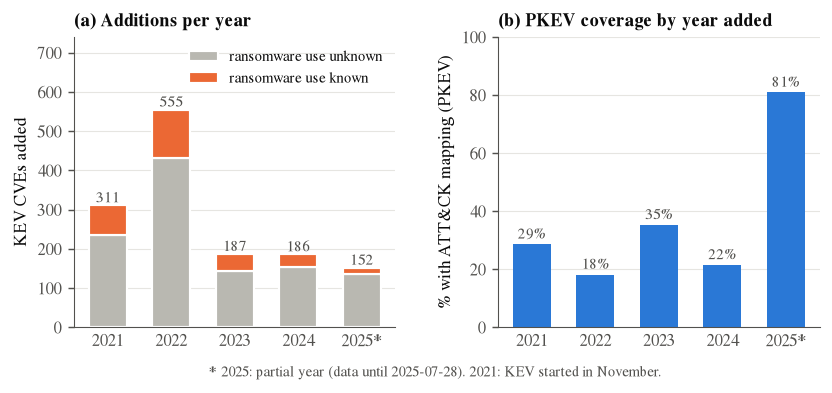

**Insight.** KEV growth peaked in 2022; the share of CVEs with an ATT&CK mapping is uneven over time (18% to 81%), highest for the newest entries.

*Figure 2. (a) CVEs added to KEV per year, split by known ransomware use. (b) Share of each year's CVEs that PKEV maps to ATT&CK. The uneven coverage is a property of the mapping, not of the vulnerabilities [cause not tested].*

In [5]:
by = vul.groupby(["year", "ransom"]).size().unstack(fill_value=0)
cov_y = vul.groupby("year").mapped.agg(["mean", "size"])
fig, (a, b) = plt.subplots(1, 2, figsize=(7.4, 2.9), gridspec_kw={"wspace": 0.32})
yrs = [str(y) + ("*" if y == 2025 else "") for y in by.index]
a.bar(yrs, by[False], color=GRAY, width=0.6, edgecolor="white", linewidth=1.2, label="ransomware use unknown")
a.bar(yrs, by[True], bottom=by[False], color=ORANGE, width=0.6, edgecolor="white", linewidth=1.2, label="ransomware use known")
for i, t in enumerate(by.sum(axis=1)): a.text(i, t + 8, f"{t}", ha="center", fontsize=8.5, color=INK2)
a.set_ylabel("KEV CVEs added"); a.set_ylim(0, 740); a.legend(loc="upper right", fontsize=8); vgrid(a); panel(a, "(a) Additions per year")
b.bar(yrs, cov_y["mean"] * 100, color=BLUE, width=0.6)
for i, (m, n) in enumerate(zip(cov_y["mean"], cov_y["size"])): b.text(i, m * 100 + 2, f"{m:.0%}", ha="center", fontsize=8.5, color=INK2)
b.set_ylabel("% with ATT&CK mapping (PKEV)"); b.set_ylim(0, 100); vgrid(b); panel(b, "(b) PKEV coverage by year added")
fig.text(0.5, -0.02, "* 2025: partial year (data until 2025-07-28). 2021: KEV started in November.", ha="center", fontsize=8, color=INK2)
finish(fig, "fig2_time", f"KEV growth peaked in 2022; the share of CVEs with an ATT&CK mapping is uneven over time ({cov_y['mean'].min():.0%} to {cov_y['mean'].max():.0%}), highest for the newest entries.",
       "Figure 2. (a) CVEs added to KEV per year, split by known ransomware use. (b) Share of each year's CVEs that PKEV maps to ATT&CK. The uneven coverage is a property of the mapping, not of the vulnerabilities [cause not tested].")

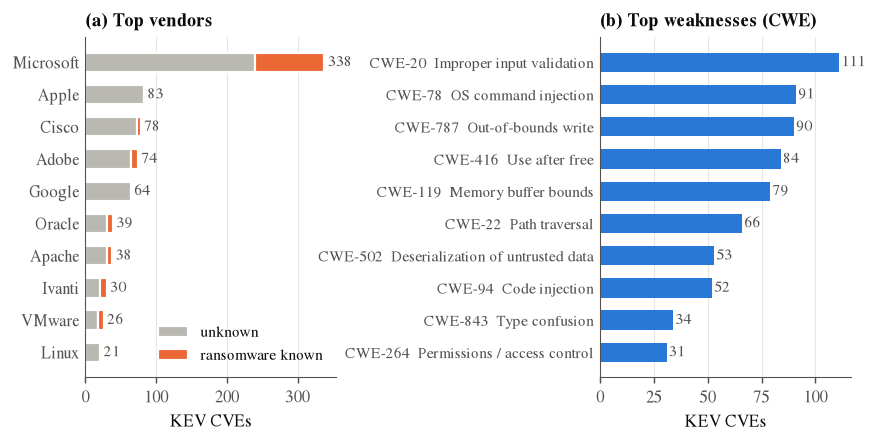

**Insight.** One vendor, Microsoft, accounts for 24% of KEV and for 34% of the ransomware-linked entries; the weaknesses are dominated by memory-safety and injection classes.

*Figure 3. (a) Ten vendors with most KEV entries; orange = part with known ransomware use. (b) Ten most frequent weaknesses assigned by KEV (CVEs per CWE). CWE names from the MITRE list.*

In [6]:
top = vul.groupby("vendor_project").agg(n=("cve_id", "size"), k=("ransom", "sum")).sort_values("n", ascending=False).head(10)
CWE_NAME = {"CWE-20": "Improper input validation", "CWE-78": "OS command injection", "CWE-787": "Out-of-bounds write", "CWE-416": "Use after free",
            "CWE-119": "Memory buffer bounds", "CWE-22": "Path traversal", "CWE-502": "Deserialization of untrusted data", "CWE-94": "Code injection",
            "CWE-843": "Type confusion", "CWE-264": "Permissions / access control", "CWE-79": "Cross-site scripting", "CWE-89": "SQL injection",
            "CWE-306": "Missing authentication", "CWE-476": "NULL pointer dereference", "CWE-125": "Out-of-bounds read", "CWE-287": "Improper authentication"}  # names: MITRE CWE list
cw = kc[kc["cwe__is_informative"]].groupby("cwe_id").cve_id.nunique().sort_values(ascending=False).head(10)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.6, 3.4), gridspec_kw={"wspace": 1.05})
y = np.arange(len(top))[::-1]
a.barh(y, top.n - top.k, color=GRAY, height=0.6, edgecolor="white", linewidth=1.2, label="unknown"); a.barh(y, top.k, left=top.n - top.k, color=ORANGE, height=0.6, edgecolor="white", linewidth=1.2, label="ransomware known")
a.set_yticks(y, top.index); a.set_xlabel("KEV CVEs"); a.legend(loc="lower right"); hgrid(a); panel(a, "(a) Top vendors")
for yy, n in zip(y, top.n): a.text(n + 5, yy, str(n), va="center", fontsize=8.5, color=INK2)
b.barh(np.arange(len(cw))[::-1], cw.values, color=BLUE, height=0.6)
b.set_yticks(np.arange(len(cw))[::-1], [f"{c}  {CWE_NAME.get(c, '')}" for c in cw.index], fontsize=8.5); b.set_xlabel("KEV CVEs"); hgrid(b); panel(b, "(b) Top weaknesses (CWE)")
for yy, n in zip(np.arange(len(cw))[::-1], cw.values): b.text(n + 1, yy, str(n), va="center", fontsize=8.5, color=INK2)
share_ms = top.loc["Microsoft", "n"] / N
finish(fig, "fig3_vendors_cwe", f"One vendor, Microsoft, accounts for {share_ms:.0%} of KEV and for {top.loc['Microsoft','k']/vul.ransom.sum():.0%} of the ransomware-linked entries; the weaknesses are dominated by memory-safety and injection classes.",
       "Figure 3. (a) Ten vendors with most KEV entries; orange = part with known ransomware use. (b) Ten most frequent weaknesses assigned by KEV (CVEs per CWE). CWE names from the MITRE list.")

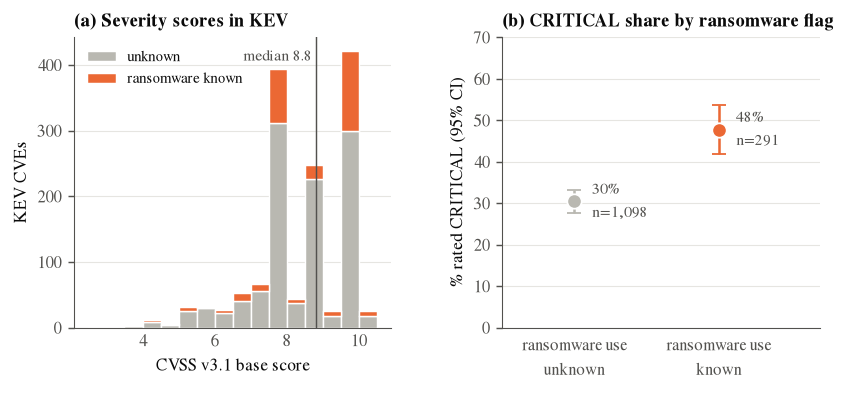

**Insight.** KEV entries are mostly HIGH or CRITICAL (median 8.8); CRITICAL is more frequent among ransomware-linked entries: +17 percentage points (95% bootstrap CI 11 to 24).

*Figure 4. (a) CVSS v3.1 base scores of KEV CVEs (1,389 with a score). (b) Share rated CRITICAL, with 95% bootstrap confidence intervals (10,000 resamples, seed 42). Association within KEV only: there is no non-KEV comparison group here.*

In [7]:
v3 = vul.dropna(subset=["cvss_v31_score"])
rng = np.random.default_rng(42)
def boot(x, n=10000): 
    m = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1); return np.percentile(m, [2.5, 97.5])
crit = {g: (v3[v3.ransom == g].cvss_v31_severity == "CRITICAL").to_numpy().astype(float) for g in (False, True)}
est = {g: crit[g].mean() for g in crit}; ci = {g: boot(crit[g]) for g in crit}
dif = rng.choice(crit[True], size=(10000, len(crit[True]))).mean(1) - rng.choice(crit[False], size=(10000, len(crit[False]))).mean(1)
dci = np.percentile(dif, [2.5, 97.5]); d0 = est[True] - est[False]
fig, (a, b) = plt.subplots(1, 2, figsize=(7.4, 2.9), gridspec_kw={"wspace": 0.35})
bins = np.arange(2.5, 10.51, 0.5)
a.hist([v3[~v3.ransom].cvss_v31_score, v3[v3.ransom].cvss_v31_score], bins=bins, stacked=True, color=[GRAY, ORANGE], edgecolor="white", linewidth=0.8, label=["unknown", "ransomware known"])
a.axvline(v3.cvss_v31_score.median(), color=INK2, linewidth=0.8); a.text(v3.cvss_v31_score.median() - 0.1, a.get_ylim()[1] * 0.92, f"median {v3.cvss_v31_score.median():.1f}", ha="right", fontsize=8.5, color=INK2)
a.set_xlabel("CVSS v3.1 base score"); a.set_ylabel("KEV CVEs"); a.legend(loc="upper left", fontsize=8); vgrid(a); panel(a, "(a) Severity scores in KEV")
for x, g, c in [(0, False, GRAY), (1, True, ORANGE)]:
    b.errorbar(x, est[g] * 100, yerr=[[(est[g] - ci[g][0]) * 100], [(ci[g][1] - est[g]) * 100]], fmt="o", color=c, markersize=8, capsize=4, linewidth=1.4, markeredgecolor="white")
    b.text(x + 0.12, est[g] * 100, f"{est[g]:.0%}\nn={len(crit[g]):,}", va="center", fontsize=8.5, color=INK2)
b.set_xlim(-0.5, 1.7); b.set_ylim(0, 70); b.set_xticks([0, 1], ["ransomware use\nunknown", "ransomware use\nknown"]); b.set_ylabel("% rated CRITICAL (95% CI)"); vgrid(b); panel(b, "(b) CRITICAL share by ransomware flag")
finish(fig, "fig4_severity", f"KEV entries are mostly HIGH or CRITICAL (median {v3.cvss_v31_score.median():.1f}); CRITICAL is more frequent among ransomware-linked entries: +{d0*100:.0f} percentage points (95% bootstrap CI {dci[0]*100:.0f} to {dci[1]*100:.0f}).",
       "Figure 4. (a) CVSS v3.1 base scores of KEV CVEs (1,389 with a score). (b) Share rated CRITICAL, with 95% bootstrap confidence intervals (10,000 resamples, seed 42). Association within KEV only: there is no non-KEV comparison group here.")
R.update(crit_share_ransom=round(est[True], 4), crit_share_other=round(est[False], 4), crit_diff_ci=[round(dci[0], 4), round(dci[1], 4)])

## 3 · Seen through ATT&CK (KEV through PKEV)

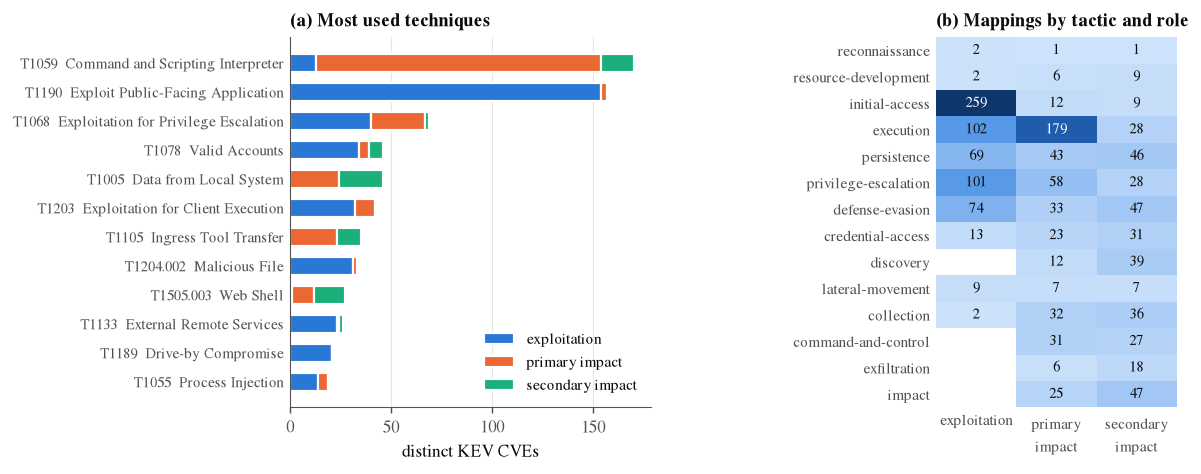

**Insight.** Exploitation mappings sit mostly in initial-access (259) and execution (102); primary impacts in execution (179). The two most used techniques, T1059 and T1190, appear in 170 and 157 of the 419 mapped CVEs.

*Figure 5. (a) Twelve most used ATT&CK techniques, as distinct KEV CVEs, split by the role PKEV gives them. (b) Number of PKEV mappings per tactic and role (a technique that belongs to several tactics counts once per tactic; empty cells blank).*

,name,CVEs
technique,,
T1059,Command and Scripting Interpreter,170
T1190,Exploit Public-Facing Application,157
T1068,Exploitation for Privilege Escalation,69
T1078,Valid Accounts,46
T1005,Data from Local System,46
T1203,Exploitation for Client Execution,43
T1105,Ingress Tool Transfer,35
T1204.002,Malicious File,33
T1505.003,Web Shell,26


In [8]:
ORDER = ["reconnaissance", "resource-development", "initial-access", "execution", "persistence", "privilege-escalation", "defense-evasion", "credential-access",
         "discovery", "lateral-movement", "collection", "command-and-control", "exfiltration", "impact"]
TYPES = ["exploitation_technique", "primary_impact", "secondary_impact"]; TCOL = dict(zip(TYPES, [BLUE, ORANGE, AQUA]))
TLAB = {"exploitation_technique": "exploitation", "primary_impact": "primary impact", "secondary_impact": "secondary impact"}
topt = mp.groupby("technique_id").agg(n=("cve_id", "nunique")).sort_values("n", ascending=False)
top12 = topt.head(12).index; ct = mp.groupby(["technique_id", "mapping_type"]).cve_id.nunique().unstack(fill_value=0).reindex(columns=TYPES, fill_value=0)
hm = mp.merge(tl, on="technique_id").groupby(["tactic", "mapping_type"]).size().unstack(fill_value=0).reindex(index=[t for t in ORDER if t in set(tl.tactic)], columns=TYPES, fill_value=0)
fig, (a, b) = plt.subplots(1, 2, figsize=(8.8, 3.7), gridspec_kw={"wspace": 0.95, "width_ratios": [1.2, 0.8]})
y = np.arange(12)[::-1]; left = np.zeros(12)
for t in TYPES:
    v = ct.loc[top12, t].to_numpy(); a.barh(y, v, left=left, color=TCOL[t], height=0.62, edgecolor="white", linewidth=1.2, label=TLAB[t]); left += v
a.set_yticks(y, [f"{t}  {Tn[t]}" for t in top12], fontsize=8.2); a.set_xlabel("distinct KEV CVEs"); a.legend(loc="lower right"); hgrid(a); panel(a, "(a) Most used techniques")
cmap = LinearSegmentedColormap.from_list("blue", SEQ); vals = hm.to_numpy().astype(float); im = b.imshow(np.where(vals > 0, vals, np.nan), cmap=cmap, aspect="auto", vmin=0, vmax=vals.max())
b.set_xticks(range(3), [TLAB[t].replace(" ", "\n") for t in TYPES], fontsize=8.3); b.set_yticks(range(len(hm)), hm.index, fontsize=8.3)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        if vals[i, j]: b.text(j, i, int(vals[i, j]), ha="center", va="center", fontsize=8, color="white" if vals[i, j] > vals.max() * 0.45 else INK)
b.tick_params(length=0); [s.set_visible(False) for s in b.spines.values()]; panel(b, "(b) Mappings by tactic and role")
finish(fig, "fig5_attack", f"Exploitation mappings sit mostly in {hm.exploitation_technique.idxmax()} ({hm.exploitation_technique.max()}) and {hm.exploitation_technique.drop(hm.exploitation_technique.idxmax()).idxmax()} ({hm.exploitation_technique.drop(hm.exploitation_technique.idxmax()).max()}); primary impacts in {hm.primary_impact.idxmax()} ({hm.primary_impact.max()}). The two most used techniques, {topt.index[0]} and {topt.index[1]}, appear in {topt.n.iloc[0]} and {topt.n.iloc[1]} of the {R['n_mapped']} mapped CVEs.",
       "Figure 5. (a) Twelve most used ATT&CK techniques, as distinct KEV CVEs, split by the role PKEV gives them. (b) Number of PKEV mappings per tactic and role (a technique that belongs to several tactics counts once per tactic; empty cells blank).")
display(pd.DataFrame({"technique": top12, "name": [Tn[t] for t in top12], "CVEs": topt.loc[top12, "n"].to_numpy()}).set_index("technique"))

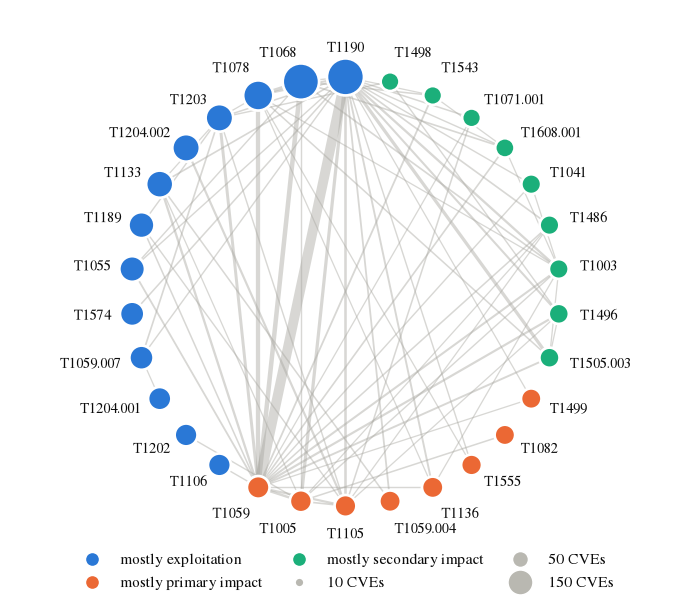

**Insight.** Techniques are not independent: 77 pairs of the 30 most used techniques appear together in at least 3 CVEs, around a hub of T1190.

*Figure 6. Technique co-occurrence network (30 most used techniques; edge = at least 3 KEV CVEs mapped to both; edge width = number of shared CVEs, node size = number of CVEs, colour = most frequent role). Circular layout, grouped by role and ordered by size.*

In [9]:
sets = mp.groupby("cve_id").technique_id.apply(lambda s: sorted(set(s)))
top30 = list(topt.head(30).index); dom = ct.idxmax(axis=1)
pairs = pd.Series([p for ts in sets for p in itertools.combinations([t for t in ts if t in top30], 2)]).value_counts()
G = nx.Graph(); G.add_nodes_from((t, {"n": int(topt.loc[t, "n"]), "role": dom[t]}) for t in top30)
G.add_edges_from((a_, b_, {"weight": int(w)}) for (a_, b_), w in pairs.items() if w >= 3)
G.remove_nodes_from(list(nx.isolates(G)))
# circular layout: nodes grouped by role (then by size), so all labels sit outside the circle and never collide
order = sorted(G, key=lambda t: (TYPES.index(G.nodes[t]["role"]), -G.nodes[t]["n"]))
ang = np.linspace(0, 2 * np.pi, len(order), endpoint=False) + np.pi / 2
pos = {t: (math.cos(a_), math.sin(a_)) for t, a_ in zip(order, ang)}
fig, ax = plt.subplots(figsize=(6.6, 6.6)); ax.axis("off"); ax.set_aspect("equal"); ax.set_xlim(-1.55, 1.55); ax.set_ylim(-1.38, 1.3)
w = np.array([G[u][v]["weight"] for u, v in G.edges])
nx.draw_networkx_edges(G, pos, ax=ax, width=0.5 + 5.0 * w / w.max(), edge_color="#a9a8a1", alpha=0.45)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[30 + 30 * math.sqrt(G.nodes[t]["n"]) for t in G], nodelist=order,
                       node_color=[TCOL[G.nodes[t]["role"]] for t in order], edgecolors="white", linewidths=1.5)
for t, a_ in zip(order, ang):
    x, y = pos[t]; ax.text(1.1 * x, 1.1 * y, t, ha="left" if x > 0.15 else "right" if x < -0.15 else "center", va="bottom" if y > 0.9 else "top" if y < -0.9 else "center", fontsize=8, color=INK)
leg = [Line2D([], [], marker="o", ls="", color=TCOL[t], markersize=8, label=f"mostly {TLAB[t]}", markeredgecolor="white") for t in TYPES]
leg += [Line2D([], [], marker="o", ls="", color=GRAY, markersize=s, label=f"{n} CVEs", markeredgecolor="white") for s, n in [(5, 10), (9, 50), (14, 150)]]
ax.legend(handles=leg, loc="lower center", ncol=3, fontsize=8.5, bbox_to_anchor=(0.5, -0.03), columnspacing=1.4)
cc = nx.connected_components(G)
finish(fig, "fig6_cooccurrence", f"Techniques are not independent: {G.number_of_edges()} pairs of the 30 most used techniques appear together in at least 3 CVEs, around a hub of {max(G.degree, key=lambda x: x[1])[0]}.",
       "Figure 6. Technique co-occurrence network (30 most used techniques; edge = at least 3 KEV CVEs mapped to both; edge width = number of shared CVEs, node size = number of CVEs, colour = most frequent role). Circular layout, grouped by role and ordered by size.")

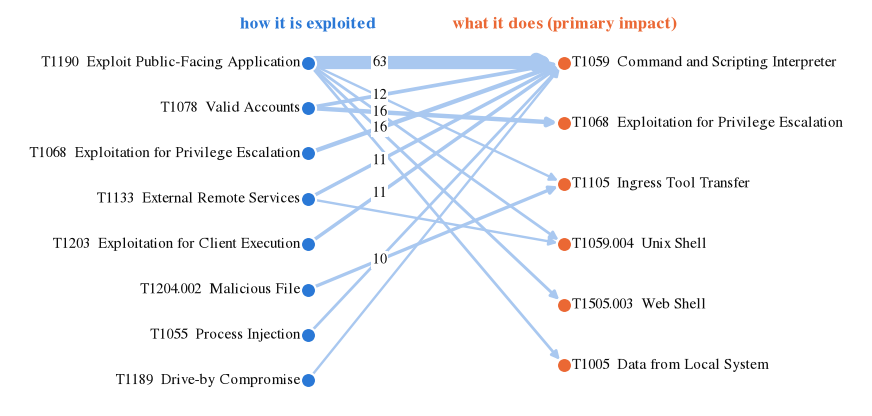

**Insight.** The most common attack story in KEV is T1190 (Exploit Public-Facing Application) followed by T1059 (Command and Scripting Interpreter): 63 CVEs, 18% of the 345 CVEs that have both roles mapped.

*Figure 7. Directed network from the exploitation technique to the primary-impact technique of the same CVE (pairs shared by at least 5 CVEs; edge width and labels = number of CVEs; labels from 10). Built from PKEV, so only the 419 mapped CVEs can appear.*

,technique_id_x,technique_id_i,CVEs,exploitation,impact
0,T1190,T1059,63,Exploit Public-Facing Application,Command and Scripting Interpreter
1,T1078,T1068,16,Valid Accounts,Exploitation for Privilege Escalation
2,T1068,T1059,16,Exploitation for Privilege Escalation,Command and Scripting Interpreter
3,T1078,T1059,12,Valid Accounts,Command and Scripting Interpreter
4,T1133,T1059,11,External Remote Services,Command and Scripting Interpreter
5,T1203,T1059,11,Exploitation for Client Execution,Command and Scripting Interpreter
6,T1204.002,T1105,10,Malicious File,Ingress Tool Transfer
7,T1190,T1505.003,8,Exploit Public-Facing Application,Web Shell


In [10]:
e = mp[mp.mapping_type == "exploitation_technique"][["cve_id", "technique_id"]].merge(mp[mp.mapping_type == "primary_impact"][["cve_id", "technique_id"]], on="cve_id", suffixes=("_x", "_i"))
flow = e.groupby(["technique_id_x", "technique_id_i"]).cve_id.nunique().sort_values(ascending=False); flow = flow[flow >= 5]
D = nx.DiGraph(); D.add_weighted_edges_from(((f"x:{a_}", f"i:{b_}", int(n)) for (a_, b_), n in flow.items()))
xs = sorted([n for n in D if n[0] == "x"], key=lambda n: -D.out_degree(n, weight="weight")); is_ = sorted([n for n in D if n[0] == "i"], key=lambda n: -D.in_degree(n, weight="weight"))
pos = {n: (0, -i) for i, n in enumerate(xs)} | {n: (1, -i * len(xs) / max(len(is_), 1)) for i, n in enumerate(is_)}
fig, ax = plt.subplots(figsize=(8.4, 3.9)); ax.axis("off")
wts = np.array([D[u][v]["weight"] for u, v in D.edges])
nx.draw_networkx_edges(D, pos, ax=ax, width=0.8 + 6.5 * wts / wts.max(), edge_color="#a9c8f0", arrows=True, arrowstyle="-|>", arrowsize=9, node_size=60, connectionstyle="arc3,rad=0")
nx.draw_networkx_nodes(D, pos, ax=ax, nodelist=xs, node_color=BLUE, node_size=70, edgecolors="white", linewidths=1.2)
nx.draw_networkx_nodes(D, pos, ax=ax, nodelist=is_, node_color=ORANGE, node_size=70, edgecolors="white", linewidths=1.2)
short = lambda t: f"{t[2:]}  {Tn[t[2:]]}"
for n in xs: ax.text(pos[n][0] - 0.03, pos[n][1], short(n), ha="right", va="center", fontsize=8.3)
for n in is_: ax.text(pos[n][0] + 0.03, pos[n][1], short(n), ha="left", va="center", fontsize=8.3)
for (u, v), wv in zip(D.edges, wts):
    if wv >= 10: ax.text(pos[u][0] + 0.28 * (pos[v][0] - pos[u][0]), pos[u][1] + 0.28 * (pos[v][1] - pos[u][1]), int(wv), ha="center", va="center", fontsize=8, color=INK, bbox=dict(fc="white", ec="none", pad=0.8), zorder=4)
ax.text(0, 0.75, "how it is exploited", ha="center", fontsize=9.5, fontweight="bold", color=BLUE); ax.text(1, 0.75, "what it does (primary impact)", ha="center", fontsize=9.5, fontweight="bold", color=ORANGE)
ax.set_xlim(-1.15, 2.15); ax.set_ylim(min(p[1] for p in pos.values()) - 0.5, 1.1)
best = flow.index[0]
finish(fig, "fig7_exploit_to_impact", f"The most common attack story in KEV is {best[0]} ({Tn[best[0]]}) followed by {best[1]} ({Tn[best[1]]}): {int(flow.iloc[0])} CVEs, {flow.iloc[0]/len(set(e.cve_id)):.0%} of the {len(set(e.cve_id))} CVEs that have both roles mapped.",
       "Figure 7. Directed network from the exploitation technique to the primary-impact technique of the same CVE (pairs shared by at least 5 CVEs; edge width and labels = number of CVEs; labels from 10). Built from PKEV, so only the 419 mapped CVEs can appear.")
display(flow.rename("CVEs").reset_index().assign(exploitation=lambda d: d.technique_id_x.map(Tn), impact=lambda d: d.technique_id_i.map(Tn)).head(8))

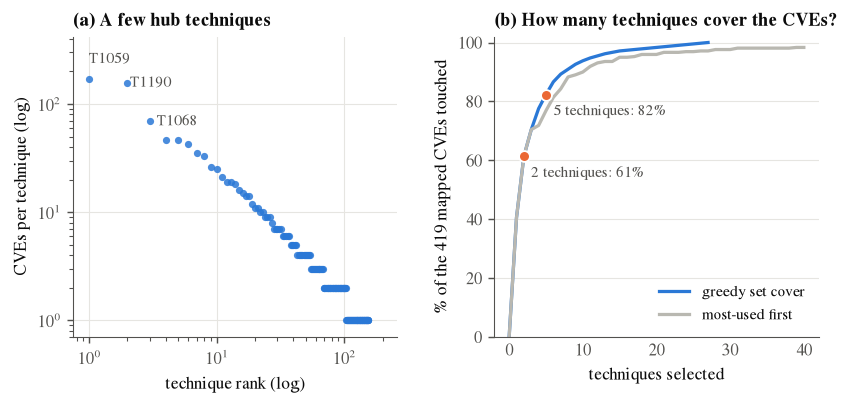

**Insight.** The CVE-technique network is one connected block (99% of nodes) with a heavy-tailed hub structure: the first 2 techniques already touch 61% of the mapped CVEs and 5 touch 82%.

*Figure 8. (a) Rank-frequency plot of techniques (log-log): number of CVEs mapped to each technique. (b) Cumulative share of mapped CVEs touched by the first k techniques, chosen greedily (set-cover heuristic) or simply most-used first.*

,value
nodes,574
CVEs,419
techniques,155
edges (distinct CVE-technique pairs),1177
connected components,3
largest component,569 (99.1%)
mean techniques per CVE,2.81
median techniques per CVE,2
median CVEs per technique,2
max CVEs per technique,170


,name,degree (CVEs),betweenness
T1059,Command and Scripting Interpreter,170,0.408
T1190,Exploit Public-Facing Application,157,0.354
T1068,Exploitation for Privilege Escalation,69,0.123
T1078,Valid Accounts,46,0.047
T1005,Data from Local System,46,0.094


top 3 by betweenness: T1059 (0.408), T1190 (0.354), T1068 (0.123)


In [11]:
# ---- graph theory on the bipartite CVE-technique network
B = nx.Graph(); ed = mp[["cve_id", "technique_id"]].drop_duplicates()
B.add_nodes_from(ed.cve_id.unique(), kind="cve"); B.add_nodes_from(ed.technique_id.unique(), kind="tech"); B.add_edges_from(ed.itertuples(index=False))
comps = sorted(nx.connected_components(B), key=len, reverse=True); giant = B.subgraph(comps[0])
tech_nodes = [n for n, d in B.nodes(data=True) if d["kind"] == "tech"]; cve_nodes = [n for n, d in B.nodes(data=True) if d["kind"] == "cve"]
deg_t = pd.Series({t: B.degree(t) for t in tech_nodes}).sort_values(ascending=False); deg_c = pd.Series({c: B.degree(c) for c in cve_nodes})
bc = nx.betweenness_centrality(B); bt = pd.Series({t: bc[t] for t in tech_nodes}).sort_values(ascending=False)
# greedy coverage: pick the technique that touches the most still-uncovered CVEs (greedy set cover)
cover = {t: set(g.cve_id) for t, g in ed.groupby("technique_id")}; left_, covd, order_g = set(cve_nodes), 0, []
curve = [0.0]
while left_ and len(order_g) < 40:
    t = max(cover, key=lambda x: len(cover[x] & left_)); order_g.append(t); left_ -= cover[t]; curve.append(1 - len(left_) / len(cve_nodes))
freq_curve = [0.0]; seen = set()
for t in deg_t.index[:40]: seen |= cover[t]; freq_curve.append(len(seen) / len(cve_nodes))
k50, k80 = next(i for i, v in enumerate(curve) if v >= 0.5), next(i for i, v in enumerate(curve) if v >= 0.8)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.4, 3.0), gridspec_kw={"wspace": 0.3})
a.loglog(np.arange(1, len(deg_t) + 1), deg_t.values, "o", color=BLUE, markersize=4, alpha=0.85, markeredgewidth=0)
a.set_ylim(0.7, 420); a.set_xlim(0.75, 260); a.text(1.0, deg_t.values[0] * 1.3, deg_t.index[0], fontsize=8.5, color=INK2, ha="left", va="bottom"); a.text(2.1, deg_t.values[1] * 1.0, deg_t.index[1], fontsize=8.5, color=INK2, va="center"); a.text(3.4, deg_t.values[2], deg_t.index[2], fontsize=8.5, color=INK2, va="center")
a.set_xlabel("technique rank (log)"); a.set_ylabel("CVEs per technique (log)"); a.grid(True, which="major"); panel(a, "(a) A few hub techniques")
b.plot(range(len(curve)), np.array(curve) * 100, color=BLUE, linewidth=1.8, label="greedy set cover"); b.plot(range(len(freq_curve)), np.array(freq_curve) * 100, color=GRAY, linewidth=1.8, label="most-used first")
b.plot([k50, k80], [curve[k50] * 100, curve[k80] * 100], "o", color=ORANGE, markersize=6, markeredgecolor="white")
b.text(k50 + 1, curve[k50] * 100 - 7, f"{k50} techniques: {curve[k50]:.0%}", fontsize=8.5, color=INK2); b.text(k80 + 1, curve[k80] * 100 - 7, f"{k80} techniques: {curve[k80]:.0%}", fontsize=8.5, color=INK2)
b.set_xlabel("techniques selected"); b.set_ylabel(f"% of the {len(cve_nodes)} mapped CVEs touched"); b.set_ylim(0, 102); b.legend(loc="lower right"); vgrid(b); panel(b, "(b) How many techniques cover the CVEs?")
finish(fig, "fig8_hubs_coverage", f"The CVE-technique network is one connected block ({len(giant)/B.number_of_nodes():.0%} of nodes) with a heavy-tailed hub structure: the first {k50} techniques already touch {curve[k50]:.0%} of the mapped CVEs and {k80} touch {curve[k80]:.0%}.",
       "Figure 8. (a) Rank-frequency plot of techniques (log-log): number of CVEs mapped to each technique. (b) Cumulative share of mapped CVEs touched by the first k techniques, chosen greedily (set-cover heuristic) or simply most-used first.")
gm = pd.DataFrame({"value": [B.number_of_nodes(), len(cve_nodes), len(tech_nodes), B.number_of_edges(), len(comps), f"{len(giant)} ({len(giant)/B.number_of_nodes():.1%})",
                             round(deg_c.mean(), 2), int(deg_c.median()), int(deg_t.median()), int(deg_t.max()), round(nx.density(B), 4)]},
                  index=["nodes", "  CVEs", "  techniques", "edges (distinct CVE-technique pairs)", "connected components", "largest component", "mean techniques per CVE", "median techniques per CVE",
                         "median CVEs per technique", "max CVEs per technique", "density"])
display(gm); hub = deg_t.head(5).index; display(pd.DataFrame({"name": [Tn[t] for t in hub], "degree (CVEs)": deg_t[hub].to_numpy(), "betweenness": bt.reindex(hub).round(3).to_numpy()}, index=hub))
print("top 3 by betweenness:", ", ".join(f"{t} ({bt[t]:.3f})" for t in bt.head(3).index))
R.update(graph=dict(nodes=B.number_of_nodes(), edges=B.number_of_edges(), components=len(comps), giant=len(giant), k50=k50, k80=k80))

## 4 · Investigations — questions asked to the database
Four questions an analyst could really ask. Each is written as **SQL** (what the relational model is for) and, when useful, as the equivalent **Django ORM** query.

In [12]:
def sql(q, params=()):
    with connection.cursor() as c:
        c.execute(q, params); cols = [d[0] for d in c.description]; return pd.DataFrame(c.fetchall(), columns=cols)
q1 = '''
SELECT vendor_project,
       COUNT(*)                                        AS cves,
       SUM(ransomware_use = 'known')                   AS ransomware_known,
       ROUND(100.0 * SUM(ransomware_use = 'known') / COUNT(*), 1) AS ransomware_pct
FROM catalog_vulnerability
GROUP BY vendor_project
HAVING COUNT(*) >= 20
ORDER BY ransomware_pct DESC
LIMIT 8;'''
print("Q1. Which vendors (>= 20 KEV CVEs) have the highest share of ransomware-linked vulnerabilities?"); print(q1); display(sql(q1))

Q1. Which vendors (>= 20 KEV CVEs) have the highest share of ransomware-linked vulnerabilities?

SELECT vendor_project,
       COUNT(*)                                        AS cves,
       SUM(ransomware_use = 'known')                   AS ransomware_known,
       ROUND(100.0 * SUM(ransomware_use = 'known') / COUNT(*), 1) AS ransomware_pct
FROM catalog_vulnerability
GROUP BY vendor_project
HAVING COUNT(*) >= 20
ORDER BY ransomware_pct DESC
LIMIT 8;


,vendor_project,cves,ransomware_known,ransomware_pct
0,Fortinet,20,13,65.0
1,VMware,26,8,30.8
2,Ivanti,30,9,30.0
3,Microsoft,338,98,29.0
4,Oracle,39,9,23.1
5,Apache,38,7,18.4
6,Adobe,74,10,13.5
7,D-Link,21,2,9.5


In [13]:
print("Q2. The worst combination: CRITICAL, ransomware-known AND an initial-access technique (PKEV) — the entry points ransomware actors used")
qs = (M.Vulnerability.objects.filter(ransomware_use="known", nvd__cvss_v31_severity="CRITICAL", mappings__technique__tactics__shortname="initial-access")
      .distinct().order_by("-nvd__cvss_v31_score", "cve_id").values("cve_id", "vendor_project", "product", "nvd__cvss_v31_score", "date_added"))
q2 = pd.DataFrame(qs); print(len(q2), "CVEs;", "the SQL generated by the ORM contains", str(qs.query).count("JOIN"), "JOINs"); display(q2.head(8))

Q2. The worst combination: CRITICAL, ransomware-known AND an initial-access technique (PKEV) — the entry points ransomware actors used
58 CVEs; the SQL generated by the ORM contains 5 JOINs


,cve_id,vendor_project,product,nvd__cvss_v31_score,date_added
0,CVE-2019-11510,Ivanti,Pulse Connect Secure,10.0,2021-11-03
1,CVE-2021-22205,GitLab,Community and Enterprise Editions,10.0,2021-11-03
2,CVE-2021-22893,Ivanti,Pulse Connect Secure,10.0,2021-11-03
3,CVE-2021-44228,Apache,Log4j2,10.0,2021-12-10
4,CVE-2023-48365,Qlik,Sense,9.9,2025-01-13
5,CVE-2010-2861,Adobe,ColdFusion,9.8,2022-03-25
6,CVE-2016-1019,Adobe,Flash Player,9.8,2022-03-03
7,CVE-2017-5638,Apache,Struts,9.8,2021-11-03


In [14]:
q3 = '''
SELECT v.cve_id, v.vendor_project, v.product, n.cvss_v31_score
FROM catalog_vulnerability v
JOIN catalog_nvdrecord n ON n.cve_id = v.cve_id
WHERE v.ransomware_use = 'known' AND n.cvss_v31_severity = 'CRITICAL'
  AND NOT EXISTS (SELECT 1 FROM catalog_pkevmapping m WHERE m.cve_id = v.cve_id)
ORDER BY v.date_added DESC;'''
print("Q3. Blind spots: ransomware-linked CRITICAL CVEs that PKEV has NOT mapped to ATT&CK (absence = 'not mapped', not 'no technique applies')")
print(q3); g3 = sql(q3); display(g3.head(6)); tot = int(((vul.ransom) & (vul.cvss_v31_severity == "CRITICAL")).sum())
print(f"=> {len(g3)} of {tot} ransomware-linked CRITICAL CVEs ({len(g3)/tot:.0%}) have no ATT&CK mapping: priority list for the next mapping effort.")
R.update(q3_unmapped=len(g3), q3_total=tot)

Q3. Blind spots: ransomware-linked CRITICAL CVEs that PKEV has NOT mapped to ATT&CK (absence = 'not mapped', not 'no technique applies')

SELECT v.cve_id, v.vendor_project, v.product, n.cvss_v31_score
FROM catalog_vulnerability v
JOIN catalog_nvdrecord n ON n.cve_id = v.cve_id
WHERE v.ransomware_use = 'known' AND n.cvss_v31_severity = 'CRITICAL'
  AND NOT EXISTS (SELECT 1 FROM catalog_pkevmapping m WHERE m.cve_id = v.cve_id)
ORDER BY v.date_added DESC;


,cve_id,vendor_project,product,cvss_v31_score
0,CVE-2025-24472,Fortinet,FortiOS and FortiProxy,9.8
1,CVE-2024-55956,Cleo,Multiple Products,9.8
2,CVE-2024-50623,Cleo,Multiple Products,9.8
3,CVE-2024-51378,CyberPersons,CyberPanel,9.8
4,CVE-2024-11667,Zyxel,Multiple Firewalls,9.8
5,CVE-2023-28461,Array Networks,AG/vxAG ArrayOS,9.8


=> 66 of 139 ransomware-linked CRITICAL CVEs (47%) have no ATT&CK mapping: priority list for the next mapping effort.


In [15]:
q4 = '''
SELECT CAST(julianday(due_date) - julianday(date_added) AS INTEGER) AS days_to_fix, COUNT(*) AS cves
FROM catalog_vulnerability GROUP BY days_to_fix ORDER BY cves DESC LIMIT 5;'''
print("Q4. How long do agencies get to fix a KEV vulnerability (due date - date added)?"); print(q4); display(sql(q4))
d4 = sql("SELECT strftime('%Y', date_added) AS year, CAST(julianday(due_date) - julianday(date_added) AS INTEGER) AS d FROM catalog_vulnerability")
med = d4.groupby("year").d.median(); neg = int(vul.due_before_added.sum())
print(f"median window by year added: {med.astype(int).to_dict()}")
print(f"=> {R['window21']/N:.0%} of entries have exactly 21 days; the median is 181 days only for 2021 (probably the initial bulk load of old CVEs [INFERENCE: not checked against CISA documentation]). {neg} entries have a due date BEFORE the added date: a source anomaly, flagged in Phase 2 (due_before_added) and kept as is.")
display(pd.DataFrame(M.Vulnerability.objects.filter(due_before_added=True).order_by("due_date").values("cve_id", "date_added", "due_date")[:3]))

Q4. How long do agencies get to fix a KEV vulnerability (due date - date added)?

SELECT CAST(julianday(due_date) - julianday(date_added) AS INTEGER) AS days_to_fix, COUNT(*) AS cves
FROM catalog_vulnerability GROUP BY days_to_fix ORDER BY cves DESC LIMIT 5;


,days_to_fix,cves
0,21,900
1,181,223
2,14,199
3,182,11
4,7,11


median window by year added: {'2021': 181, '2022': 21, '2023': 21, '2024': 21, '2025': 21}
=> 65% of entries have exactly 21 days; the median is 181 days only for 2021 (probably the initial bulk load of old CVEs [INFERENCE: not checked against CISA documentation]). 15 entries have a due date BEFORE the added date: a source anomaly, flagged in Phase 2 (due_before_added) and kept as is.


,cve_id,date_added,due_date
0,CVE-2020-0601,2021-11-03,2020-01-29
1,CVE-2020-1350,2021-11-03,2020-07-24
2,CVE-2020-1472,2021-11-03,2020-09-21


*Reading Q1–Q4:* the relational model makes cross-source questions one query (Q2 joins KEV, NVD, PKEV and ATT&CK; Q3 uses an anti-join, `NOT EXISTS`). Q3 and Q4 also show the value of the **missing ≠ empty** rule from Phase 2: an absent mapping and a flagged anomaly are reported, not hidden or guessed.

## 5 · One CVE through the four sources

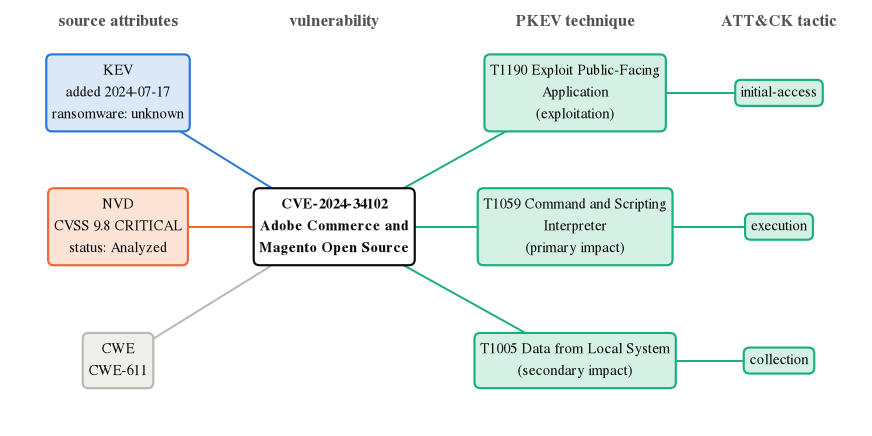

**Insight.** CVE-2024-34102 (Adobe Commerce and Magento Open Source) is a single node that carries facts from four sources: KEV says it is exploited, NVD scores it 9.8, 3 PKEV mapping(s) say how, ATT&CK places them in 3 tactic(s).

*Figure 9. One vulnerability across the four sources. Blue = CISA KEV, orange = NVD, aqua = ATT&CK (techniques via the PKEV mapping, then tactics), gray = weakness (CWE). Function case_figure(cve_id) draws the same figure for any CVE.*

In [16]:
def case_figure(cve_id, name="fig9_case_study"):
    v = M.Vulnerability.objects.select_related("nvd").get(pk=cve_id); n = v.nvd
    cwes = sorted({c.cwe_id for c in v.cwes.all()} | {x.cwe_id for x in n.nvdcvecwe_set.all()})
    maps = sorted({(m.technique_id, m.mapping_type) for m in v.mappings.all()}, key=lambda x: (TYPES.index(x[1]), x[0]))
    tact = {t: sorted(M.AttackTechnique.objects.get(pk=t).tactics.values_list("shortname", flat=True)) for t, _ in maps}
    tactics = sorted({s for ss in tact.values() for s in ss}, key=ORDER.index)
    X = [0.0, 1.75, 3.7, 5.35]
    spread = lambda k, lo, hi: [(lo + hi) / 2] if k == 1 else list(np.linspace(hi, lo, k))
    H = max(len(maps), len(tactics), 4) - 1
    fig, ax = plt.subplots(figsize=(8.4, 0.62 * (H + 2) + 1.0)); ax.axis("off"); ax.set_xlim(-0.85, 6.0); ax.set_ylim(-0.7, H + 0.9)
    mid = H / 2
    def box(x, y, text, fc, ec, bold=False):
        ax.text(x, y, text, ha="center", va="center", fontsize=8, fontweight="bold" if bold else "normal", color=INK, zorder=3,
                bbox=dict(boxstyle="round,pad=0.4", fc=fc, ec=ec, lw=1.2))
    def link(p, q, c="#b9b8b1"): ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=1.1, zorder=1, solid_capstyle="round")
    left = [("KEV", f"added {v.date_added}\nransomware: {v.ransomware_use}", "#dbe8f7", BLUE, mid + 1.5),
            ("NVD", f"CVSS {n.cvss_v31_score} {n.cvss_v31_severity}\nstatus: {n.vuln_status}", "#fbe3d6", ORANGE, mid),
            ("CWE", "\n".join(cwes) if cwes else "none", "#eeeeea", GRAY, mid - 1.5)]
    box(X[1], mid, f"{v.cve_id}\n" + "\n".join(textwrap.wrap(f"{v.vendor_project} {v.product}", 20)), "white", INK, bold=True)
    for lab, txt, fc, ec, y in left:
        box(X[0], y, f"{lab}\n{txt}", fc, ec); link((X[0], y), (X[1], mid), ec)
    ty = spread(len(maps), 0, H); ay = spread(len(tactics), 0, H); yt = dict(zip([m[0] for m in maps], ty)); ya = dict(zip(tactics, ay))
    for (t, role), y in zip(maps, ty):
        box(X[2], y, f"{t} " + "\n".join(textwrap.wrap(Tn[t], 22)) + f"\n({TLAB[role]})", "#d5f1e6", AQUA); link((X[1], mid), (X[2], y), AQUA)
        for s in tact[t]: link((X[2], y), (X[3], ya[s]), AQUA)
    for s, y in ya.items(): box(X[3], y, s, "#d5f1e6", AQUA)
    for x, lab in zip(X, ["source attributes", "vulnerability", "PKEV technique", "ATT&CK tactic"]): ax.text(x, H + 0.75, lab, ha="center", fontsize=9, fontweight="bold", color=INK2)
    return fig, v, n, cwes, maps, tactics

CASE = "CVE-2024-34102"
fig, v, n, cwes, maps, tactics = case_figure(CASE)
finish(fig, "fig9_case_study", f"{CASE} ({v.vendor_project} {v.product}) is a single node that carries facts from four sources: KEV says it is exploited, NVD scores it {n.cvss_v31_score}, {len(maps)} PKEV mapping(s) say how, ATT&CK places them in {len(tactics)} tactic(s).",
       "Figure 9. One vulnerability across the four sources. Blue = CISA KEV, orange = NVD, aqua = ATT&CK (techniques via the PKEV mapping, then tactics), gray = weakness (CWE). Function case_figure(cve_id) draws the same figure for any CVE.")

## 6 · How FAIR is it? (honest self-assessment)
Status is what the project **actually did and tested**, not what would be possible. Evidence points to the validation phase where it is checked.

In [17]:
fair = [
 ("F1", "Globally unique, persistent identifiers", "partial", "CVE, CWE and ATT&CK entities use their public IRIs; the own vocabulary namespace is a placeholder (example.org). Phase 4"),
 ("F2", "Rich metadata", "done", "DCAT + PROV description of the whole dataset at /api/dataset/. Phase 4"),
 ("F3", "Metadata include the data identifier", "done", "Distributions carry URL and SHA-256 (NVD: hash of the file manifest, 1,391 files). Phases 1, 4"),
 ("F4", "Registered in a searchable resource", "not done", "No registry, DOI or Zenodo deposit; the API is local"),
 ("A1", "Retrievable by a standard protocol", "partial", "HTTP + content negotiation (JSON, JSON-LD); tested on a local server only. Phase 4"),
 ("A2", "Metadata remain available if the data go", "not done", "Snapshots keep data and manifest, but nothing external keeps the metadata alive. Phase 5"),
 ("I1", "Formal, shared knowledge representation", "done", "JSON-LD; RDF round trip and SPARQL tested with rdflib / PyLD. Phase 4, jsonld_demo"),
 ("I2", "FAIR vocabularies", "partial", "DCAT, PROV, DCTERMS reused; domain terms are in the placeholder vocabulary"),
 ("I3", "Qualified references to other data", "done", "Links to CWE and ATT&CK IRIs; PKEV mapping reified as its own node. Phase 4"),
 ("R1.1", "Clear data usage license", "partial", "Licenses recorded per source; the PKEV data license is UNCERTAIN"),
 ("R1.2", "Detailed provenance", "done", "Raw SHA-256, cleaning log, snapshot manifest chained with wasRevisionOf. Phases 1, 2, 5"),
 ("R1.3", "Community standards", "partial", "CVE / CWE / ATT&CK identifiers and DCAT / PROV used; no formal conformance test"),
]
F = pd.DataFrame(fair, columns=["principle", "meaning", "status", "evidence"]).set_index("principle")
sym = {"done": "✓ done", "partial": "◐ partial", "not done": "✗ not done"}
pd.set_option("display.max_colwidth", 200); display(F.assign(status=F.status.map(sym)))
cnt = F.status.value_counts(); print({k: int(cnt.get(k, 0)) for k in ["done", "partial", "not done"]}, "of", len(F), "(self-assessment, not an external audit)")
R["fair"] = {k: int(cnt.get(k, 0)) for k in ["done", "partial", "not done"]}

,meaning,status,evidence
principle,,,
F1,"Globally unique, persistent identifiers",◐ partial,"CVE, CWE and ATT&CK entities use their public IRIs; the own vocabulary namespace is a placeholder (example.org). Phase 4"
F2,Rich metadata,✓ done,DCAT + PROV description of the whole dataset at /api/dataset/. Phase 4
F3,Metadata include the data identifier,✓ done,"Distributions carry URL and SHA-256 (NVD: hash of the file manifest, 1,391 files). Phases 1, 4"
F4,Registered in a searchable resource,✗ not done,"No registry, DOI or Zenodo deposit; the API is local"
A1,Retrievable by a standard protocol,◐ partial,"HTTP + content negotiation (JSON, JSON-LD); tested on a local server only. Phase 4"
A2,Metadata remain available if the data go,✗ not done,"Snapshots keep data and manifest, but nothing external keeps the metadata alive. Phase 5"
I1,"Formal, shared knowledge representation",✓ done,"JSON-LD; RDF round trip and SPARQL tested with rdflib / PyLD. Phase 4, jsonld_demo"
I2,FAIR vocabularies,◐ partial,"DCAT, PROV, DCTERMS reused; domain terms are in the placeholder vocabulary"
I3,Qualified references to other data,✓ done,Links to CWE and ATT&CK IRIs; PKEV mapping reified as its own node. Phase 4


{'done': 5, 'partial': 5, 'not done': 2} of 12 (self-assessment, not an external audit)


## 7 · Limits — what these results do **not** say
- **Selection.** KEV contains only vulnerabilities with evidence of exploitation that CISA chose to list. Shares and averages describe KEV, not "all CVEs"; the ransomware flag is the one KEV knows about at the time of listing.
- **PKEV covers 30%.** Every ATT&CK result (Figures 5–9, Q2, Q3) is about the 419 mapped CVEs. Coverage varies by year (Fig. 2b) for reasons not tested here, so counts by technique may reflect what was mapped, not what attackers did. *Absence of a mapping is "not mapped", never "no technique applies".*
- **Association is not cause.** The higher CRITICAL share among ransomware-linked entries (Fig. 4b) has a confidence interval from resampling the same KEV rows; it does not show that severity attracts ransomware.
- **Partial year.** 2025 ends on 2025-07-28; counts for that year are not comparable with full years.
- **Source quality.** NVD comes from an unofficial mirror (fkie-cad); 15 KEV entries have a due date before the added date (kept and flagged); PKEV mapping ids are positional.
- **Snapshots/diff** were proved on a synthetic second version, not on two real releases.
- **Scope of FAIR.** Section 6 is our own assessment; F4 and A2 are not addressed.

In [18]:
# ---- save captions and key numbers so the report/slides can reuse them verbatim
(FIG / "captions.md").write_text("# Figure captions and insights\n\n" + "\n".join(f"## {k}\n\n**Insight.** {i}\n\n*{c}*\n" for k, (i, c) in CAPTIONS.items()), encoding="utf-8")
R["figures"] = sorted(CAPTIONS)
(ROOT / "docs" / "results_key_numbers.json").write_text(json.dumps(R, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
print(len(CAPTIONS), "figures (PNG + PDF) in", FIG.relative_to(ROOT)); print("key numbers -> docs/results_key_numbers.json")
assert len(CAPTIONS) == 9 and all((FIG / f"{k}.png").stat().st_size > 5000 and (FIG / f"{k}.pdf").exists() for k in CAPTIONS)

9 figures (PNG + PDF) in docs/figures
key numbers -> docs/results_key_numbers.json


## Summary for the presentation
1. **Integration works**: one `CVE` key joins four sources; every headline number was recounted independently from the CSV files (Part 0), and each earlier phase passed its own gate (Part 1).
2. **KEV facts**: concentrated in few vendors and in memory-safety / injection weaknesses; mostly HIGH–CRITICAL; ransomware-linked entries are more often CRITICAL (association).
3. **ATT&CK view**: a handful of techniques (initial access → execution) explain most mapped CVEs; the network is one connected block with hubs (Figs 6–8).
4. **Questions become queries**: Q1–Q4 show cross-source analysis in SQL/ORM; Q3 turns the PKEV gap into a priority list.
5. **Honest limits**: KEV selection, 30% mapping coverage, partial 2025, FAIR gaps F4 and A2.